# 01. Exploratory Data Analysis (EDA)

**Purpose:** Understand the structure, distribution, and quality of the Deezer dataset

**Outputs:** No saved files (display only). Key findings inform 02_preprocessing

**Key Findings:**
- 7.5M interactions, 19.9K users, 452.9K items, 2922 genres
- Target: 68% listened, 32% skipped (slightly imbalanced)
- Platform & listen_type are predictive; age/gender are weak
- Data is 99.92% sparse (requires smart feature engineering)

**Next:** 02_preprocessing.ipynb

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Config
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

In [ ]:
import os
import sys

try:
    from google.colab import drive
    drive.mount('/content/gdrive')
    base_path = '/content/gdrive/MyDrive/Recommender Systems (Project)/'
    print('Using Google Colab path')
except:
    base_path = './'  # Local path
    print('Using local path')

df_train = pd.read_csv(base_path + 'train.csv')

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).
Using Google Colab path


## 1. Dataset Overview
  - How many rows and columns?                                                                    
  - What's the shape/size?                                                                        
  - Column names and data types?                                                                  
  - Any immediate issues?   

In [ ]:
df_train.head()

,genre_id,ts_listen,media_id,album_id,context_type,release_date,platform_name,platform_family,media_duration,listen_type,user_gender,user_id,artist_id,user_age,is_listened
0,25471,1480597215,222606,41774,12,20040704,1,0,223,0,0,9241,55164,29,0
1,25571,1480544735,250467,43941,0,20060301,2,1,171,0,0,16547,55830,30,1
2,16,1479563953,305197,48078,1,20140714,2,1,149,1,1,7665,2704,29,1
3,7,1480152098,900502,71521,0,20001030,0,0,240,0,1,1580,938,30,0
4,7,1478368974,542335,71718,0,20080215,0,0,150,0,1,1812,2939,24,1


In [ ]:
df_train.shape

(7558834, 15)

In [ ]:
df_train.describe()

,genre_id,ts_listen,media_id,album_id,context_type,release_date,platform_name,platform_family,media_duration,listen_type,user_gender,user_id,artist_id,user_age,is_listened
count,7.558834e+06,7.558834e+06,7.558834e+06,7.558834e+06,7.558834e+06,7.558834e+06,7.558834e+06,7.558834e+06,7.558834e+06,7.558834e+06,7.558834e+06,7.558834e+06,7.558834e+06,7.558834e+06,7.558834e+06
mean,2.245030e+03,1.479011e+09,7.839624e+07,8.136169e+06,2.360018e+00,2.011388e+07,4.731900e-01,2.558086e-01,2.311527e+02,3.068742e-01,3.936884e-01,4.037300e+03,1.500740e+06,2.431278e+01,6.840330e-01
std,1.308979e+04,1.189935e+07,5.133633e+07,5.460090e+06,4.659856e+00,7.570138e+04,7.353008e-01,5.481663e-01,7.999463e+01,4.611968e-01,4.885672e-01,3.954754e+03,2.519546e+06,3.767797e+00,4.648999e-01
min,0.000000e+00,1.000000e+00,2.000580e+05,1.976000e+03,0.000000e+00,1.900010e+07,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.800000e+01,0.000000e+00
25%,0.000000e+00,1.478460e+09,1.376614e+07,1.255566e+06,0.000000e+00,2.009123e+07,0.000000e+00,0.000000e+00,1.960000e+02,0.000000e+00,0.000000e+00,8.990000e+02,2.605000e+03,2.100000e+01,0.000000e+00
50%,3.000000e+00,1.479057e+09,9.380660e+07,9.525626e+06,1.000000e+00,2.014103e+07,0.000000e+00,0.000000e+00,2.220000e+02,0.000000e+00,0.000000e+00,2.738000e+03,1.941720e+05,2.500000e+01,1.000000e+00
75%,2.700000e+01,1.479742e+09,1.262592e+08,1.329221e+07,2.000000e+00,2.016061e+07,1.000000e+00,0.000000e+00,2.540000e+02,1.000000e+00,1.000000e+00,6.064000e+03,1.519461e+06,2.800000e+01,1.000000e+00
max,2.597310e+05,1.480636e+09,1.372601e+08,1.472086e+07,7.300000e+01,3.000010e+07,2.000000e+00,2.000000e+00,6.553500e+04,1.000000e+00,1.000000e+00,1.991700e+04,1.144741e+07,3.000000e+01,1.000000e+00


Mean of target variable `is_listened` is about 68% which is an imbalance to be aware of. However, its not severe but could have impact when building models later.

Max `media_duration` of 65,535 (6.553500e+04) is suspicious. Therefore we need to validate how much rows have such high values.

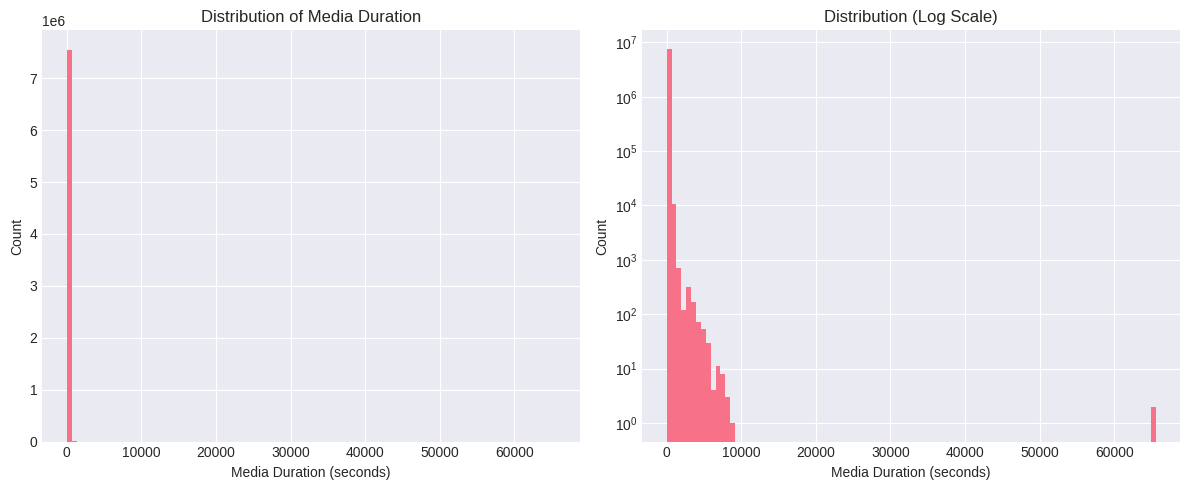

In [ ]:
import matplotlib.pyplot as plt

# Plot histogram of media_duration
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.hist(df_train['media_duration'], bins=100)
plt.xlabel('Media Duration (seconds)')
plt.ylabel('Count')
plt.title('Distribution of Media Duration')

plt.subplot(1, 2, 2)
plt.hist(df_train['media_duration'], bins=100)
plt.xlabel('Media Duration (seconds)')
plt.ylabel('Count')
plt.title('Distribution (Log Scale)')
plt.yscale('log')

plt.tight_layout()
plt.show()

In [ ]:
df_train[df_train['media_duration'] == 65535].shape[0]

2

Only 2 rows of 7.5 million seems to be negligible.

In [ ]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7558834 entries, 0 to 7558833
Data columns (total 15 columns):
 #   Column           Dtype
---  ------           -----
 0   genre_id         int64
 1   ts_listen        int64
 2   media_id         int64
 3   album_id         int64
 4   context_type     int64
 5   release_date     int64
 6   platform_name    int64
 7   platform_family  int64
 8   media_duration   int64
 9   listen_type      int64
 10  user_gender      int64
 11  user_id          int64
 12  artist_id        int64
 13  user_age         int64
 14  is_listened      int64
dtypes: int64(15)
memory usage: 865.0 MB


In [ ]:
df_train.dtypes

,0
genre_id,int64
ts_listen,int64
media_id,int64
album_id,int64
context_type,int64
release_date,int64
platform_name,int64
platform_family,int64
media_duration,int64
listen_type,int64


Let's continue with the categorical features.

  - How many unique categories in each column                                                     
  - Are they balanced or imbalanced? (some categories much more frequent?)                        
  - Any missing values?   

In [ ]:
print(df_train['platform_name'].value_counts())
print("##############################")
print(df_train['platform_family'].value_counts())
print("##############################")
print(df_train['context_type'].nunique())
print("##############################")
print(df_train['listen_type'].value_counts())

platform_name
0    5083338
1    1374227
2    1101269
Name: count, dtype: int64
##############################
platform_family
0    6041392
1    1101269
2     416173
Name: count, dtype: int64
##############################
74
##############################
listen_type
0    5239223
1    2319611
Name: count, dtype: int64


 The features have different cardinality (number of unique values):            
  - Some categorical with few values (platform_name: 3)                                           
  - Some with many values (context_type: 74, and IDs like artist_id, media_id have millions)

In [ ]:
# Checking missing values
df_train.isnull().sum()

,0
genre_id,0
ts_listen,0
media_id,0
album_id,0
context_type,0
release_date,0
platform_name,0
platform_family,0
media_duration,0
listen_type,0


No missing values — the dataset is clean.

### Summary
  - **7.5M rows**, 15 columns                                                                         
  - **No missing values**                                                                             
  - **All encoded as integers** (some truly numeric, most categorical)                                
  - **Target** `is_listened`: 68% positive, 32% negative (slightly imbalanced)                          
  - **Categorical features**: platform_name (3), platform_family (3), context_type (74), listen_type  
  (2), user_gender (2), etc.                                                                      
  - **ID/entity features**: user_id, media_id, artist_id, album_id, genre_id (millions of unique      
  values)

## 2. Target Variable & Feature Relationships

  - Do different platforms have different listen rates?                                           
  - Do certain ages listen more/less?                                                             
  - Do short/long songs get listened to differently?

In [ ]:
# 1. Breakdown of is_listened by each categorical feature
print(df_train.groupby('platform_name')['is_listened'].mean())
print("##############################")
print(df_train.groupby('listen_type')['is_listened'].mean())
print("##############################")
print(df_train.groupby('user_gender')['is_listened'].mean())

platform_name
0    0.637593
1    0.706144
2    0.870803
Name: is_listened, dtype: float64
##############################
listen_type
0    0.721113
1    0.600282
Name: is_listened, dtype: float64
##############################
user_gender
0    0.697240
1    0.663693
Name: is_listened, dtype: float64


**Insight:**
- Platform matters! Platform 2 users are much more likely to listen.
- Listen type affects likelihood. Type 0 users listen more.
- Gender has weak effect on listening behavior.

In [ ]:
# 2. For numerical features, compare distributions
print(df_train[df_train['is_listened'] == 1]['user_age'].describe())
print("##############################")
print(df_train[df_train['is_listened'] == 0]['user_age'].describe())
print("##############################")
print(df_train[df_train['is_listened'] == 1]['media_duration'].describe())
print("##############################")
print(df_train[df_train['is_listened'] == 0]['media_duration'].describe())


count    5.170492e+06
mean     2.452028e+01
std      3.774134e+00
min      1.800000e+01
25%      2.100000e+01
50%      2.500000e+01
75%      2.800000e+01
max      3.000000e+01
Name: user_age, dtype: float64
##############################
count    2.388342e+06
mean     2.386356e+01
std      3.714539e+00
min      1.800000e+01
25%      2.100000e+01
50%      2.400000e+01
75%      2.700000e+01
max      3.000000e+01
Name: user_age, dtype: float64
##############################
count    5.170492e+06
mean     2.313201e+02
std      8.396455e+01
min      0.000000e+00
25%      1.950000e+02
50%      2.220000e+02
75%      2.540000e+02
max      6.553500e+04
Name: media_duration, dtype: float64
##############################
count    2.388342e+06
mean     2.307904e+02
std      7.063862e+01
min      0.000000e+00
25%      1.970000e+02
50%      2.230000e+02
75%      2.530000e+02
max      7.575000e+03
Name: media_duration, dtype: float64


**Insight:**
- Age has minimal effect on listening behavior.
- Song length doesn't strongly predict listening (contradicts intuition, interesting!)

### Summary
  **Strong predictors:**                                                                              
  - platform_name (63% → 87% listen rate)                                                         
  - listen_type (60% → 72% listen rate)                                                           
                                                                                                  
  **Weak predictors:**                                                                                
  - user_age (barely different)                                                                   
  - media_duration (nearly identical)                                                             
  - user_gender (weak difference)   

## User & Item Coverage (Sparsity)

For recommender systems, sparsity is critical — how many users/items? How active are they?

In [ ]:
print(f"Unique users: {df_train['user_id'].nunique()}")
print(f"Unique items (media): {df_train['media_id'].nunique()}")
print(f"Unique artists: {df_train['artist_id'].nunique()}")
print(f"Unique genres: {df_train['genre_id'].nunique()}")

# Distribution: are some users/items very active?
print(df_train['user_id'].value_counts().describe())
print(df_train['media_id'].value_counts().describe())

Unique users: 19918
Unique items (media): 452975
Unique artists: 67142
Unique genres: 2922
count    19918.000000
mean       379.497640
std        508.267514
min          1.000000
25%         66.000000
50%        197.000000
75%        495.000000
max       6317.000000
Name: count, dtype: float64
count    452975.000000
mean         16.687089
std         160.707867
min           1.000000
25%           1.000000
50%           2.000000
75%           5.000000
max       20148.000000
Name: count, dtype: float64


**Users:**
  - 19,918 users                                                                                  
  - Mean: 379 interactions per user (median 197)                                                  
  - Range: 1 to 6,317                                                                             
  - Some power users with thousands of interactions

  **Items (media):**                                                                                  
  - 452,975 items                                                                                 
  - Mean: 16.7 interactions per item                                                              
  - **Median: 2 interactions!** <- Most songs are rarely played                                        
  - Range: 1 to 20,148                                                                            
  - Few blockbuster songs, many obscure ones  


  **The Problem:** You have 7.5M interactions spread across 452K items. Most songs are played only 1-5
   times.

How much of the user-item matrix is empty?

In [ ]:
# Calculate sparsity
total_possible_interactions = 19918 * 452975
actual_interactions = len(df_train)
sparsity = 1 - (actual_interactions / total_possible_interactions)
print(f"Sparsity: {sparsity:.6f}")  # What % of user-item pairs are NOT in the data?

Sparsity: 0.999162


  - Only **0.08% of possible user-item pairs** have data                                              
  - 99.92% of the matrix is unknown                                                               
  - This is why recommenders are hard: you're predicting in mostly empty space!

  **Why this matters:**
  1. **Collaborative filtering alone won't work well** – not enough user-user or item-item overlap    
  2. **Content-based features are crucial** – you'll rely heavily on genre, artist, platform, context
  3. **Popular items dominate** – your model will bias toward recommending hit songs                  
  4. **Cold start is real** – new users/songs are hard to handle  

## Summary

  - **Dataset:** 7.5M interactions, 19.9K users, 452.9K items, 2922 genres                            
  - **Target balance:** 68% listened, 32% skipped                                                     
  - **Feature predictive power:** Platform & listen_type matter; age/gender weak                      
  - **Sparsity:** 99.92% – highly sparse, requires smart approaches